# Clase N°8 - Modelo de Machine Learning no supervisado con K-Means
## Segmentacion de clientes

**Autor:** Ariel Tuñon  
**Curso:** Aprendizaje Automático 2026 — Politécnico Superior Malvinas Argentinas

---

### Trabajamos con el **dataset_segmentacion_clientes.csv**; que contiene los siguientes datos sobre clientes:

**Dataset (columnas):**
1. `purchase_freq_month` — frecuencia de compras por mes (escala baja a media).  
2. `avg_basket_usd` — ticket/promedio por compra en USD (escala media a alta).  
3. `time_on_site_min` — tiempo de permanencia en el sitio (minutos).  
4. `discount_sensitivity` — sensibilidad a descuentos (0 a 1).  
5. `returns_rate` — tasa de devoluciones (0 a 0.8 aprox.).

## Objetivo

El objetivo es aplicar técnicas de aprendizaje no supervisado utilizando el algoritmo **K-Means** para identificar segmentos de clientes a partir de sus comportamientos de compra y navegación en un sitio web.

Se trabajará con un dataset de clientes que contiene variables relacionadas con:
- frecuencia de compra
- ticket promedio
- tiempo de permanencia en el sitio
- sensibilidad a descuentos
- tasa de devoluciones

Además, se utilizarán:
- escalado de variables
- método del codo
- Silhouette Score
- análisis de centroides
- visualizaciones de clusters




## Importar librerías

Usaremos pandas y NumPy para trabajar con los datos, Matplotlib y Seaborn para visualizarlos, y scikit-learn para preparar las variables y entrenar K-Means.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## Cargar el dataset

### Se carga el dataset proporcionado en el campus virtual.


In [2]:
import pandas as pd

url_github = "https://raw.githubusercontent.com/arieltunon74/Aprendizaje_Automatico_2026/main/Clase8/Datos/dataset_segmentacion_clientes.csv"

try:
    print("Descargando dataset desde GitHub...")
    df = pd.read_csv(url_github, low_memory=False)
    print("Dataset descargado correctamente desde la web.")
except Exception as e:
    raise RuntimeError(
        f"No se pudo descargar el dataset desde GitHub. Verificá la URL o tu conexión. Detalle: {e}"
    )

df.columns = df.columns.str.strip().str.lower()
print("Dimensiones:", df.shape)
display(df.head())

Descargando dataset desde GitHub...
Dataset descargado correctamente desde la web.
Dimensiones: (700, 7)


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


## Eliminar columnas noise_gauss y noise_uniform que no serán usadas en el análisis

In [3]:
# Drop noise_gauss, noise_uniform

datos_csv_limpios = df.drop(["noise_gauss", "noise_uniform"], axis=1)
datos_csv_limpios.describe()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
count,700.000000,700.000000,700.000000,700.000000,700.000000
mean,5.875724,248.173491,16.784799,0.425083,0.337194
std,4.471079,154.904372,12.914111,0.431467,0.356623
min,0.100000,86.994100,3.163206,0.000000,0.000000
25%,2.278418,90.766945,6.603950,0.000000,0.000000
50%,4.134580,180.223799,9.974407,0.296475,0.165559
75%,11.214919,449.719033,34.341360,1.000000,0.800000
max,14.603388,452.973583,38.348156,1.000000,0.800000


## Inspección inicial de los datos

Revisamos los nombres de las columnas, los tipos de datos, los valores faltantes y las estadísticas descriptivas. Esto permite seleccionar variables disponibles y detectar problemas antes del modelado.

In [4]:
datos_csv_limpios.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
dtypes: float64(5)
memory usage: 27.5 KB


In [5]:
import pandas as pd

def info_vistoso(df):
    resumen = pd.DataFrame({
        'Tipo de Dato': df.dtypes,
        'No Nulos': df.notnull().sum(),
        'Nulos': df.isnull().sum(),
        '% Nulos': (df.isnull().sum() / len(df) * 100).round(2).astype(str) + '%',
        'Valores Únicos': df.nunique(),
        'Memoria (KB)': (df.memory_usage(deep=True) / 1024).round(2)
    })

    # Información general del DataFrame
    print(f"📊 **Resumen del DataFrame**")
    print(f"• Total de Filas: {len(df):,}")
    print(f"• Total de Columnas: {df.shape[1]}")
    print(f"• Memoria Total: {df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB\n")

    return resumen

# Ejecutalo así:
info_vistoso(datos_csv_limpios)


📊 **Resumen del DataFrame**
• Total de Filas: 700
• Total de Columnas: 5
• Memoria Total: 0.03 MB



,Tipo de Dato,No Nulos,Nulos,% Nulos,Valores Únicos,Memoria (KB)
Index,NaN,NaN,NaN,NaN,NaN,0.13
avg_basket_usd,float64,700.0,0.0,0.0%,700.0,5.47
discount_sensitivity,float64,700.0,0.0,0.0%,245.0,5.47
purchase_freq_month,float64,700.0,0.0,0.0%,690.0,5.47
returns_rate,float64,700.0,0.0,0.0%,199.0,5.47
time_on_site_min,float64,700.0,0.0,0.0%,700.0,5.47


## Análisis Estadístico

In [6]:
datos_csv_limpios.describe()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
count,700.000000,700.000000,700.000000,700.000000,700.000000
mean,5.875724,248.173491,16.784799,0.425083,0.337194
std,4.471079,154.904372,12.914111,0.431467,0.356623
min,0.100000,86.994100,3.163206,0.000000,0.000000
25%,2.278418,90.766945,6.603950,0.000000,0.000000
50%,4.134580,180.223799,9.974407,0.296475,0.165559
75%,11.214919,449.719033,34.341360,1.000000,0.800000
max,14.603388,452.973583,38.348156,1.000000,0.800000


## Pre-visualización de los datos:

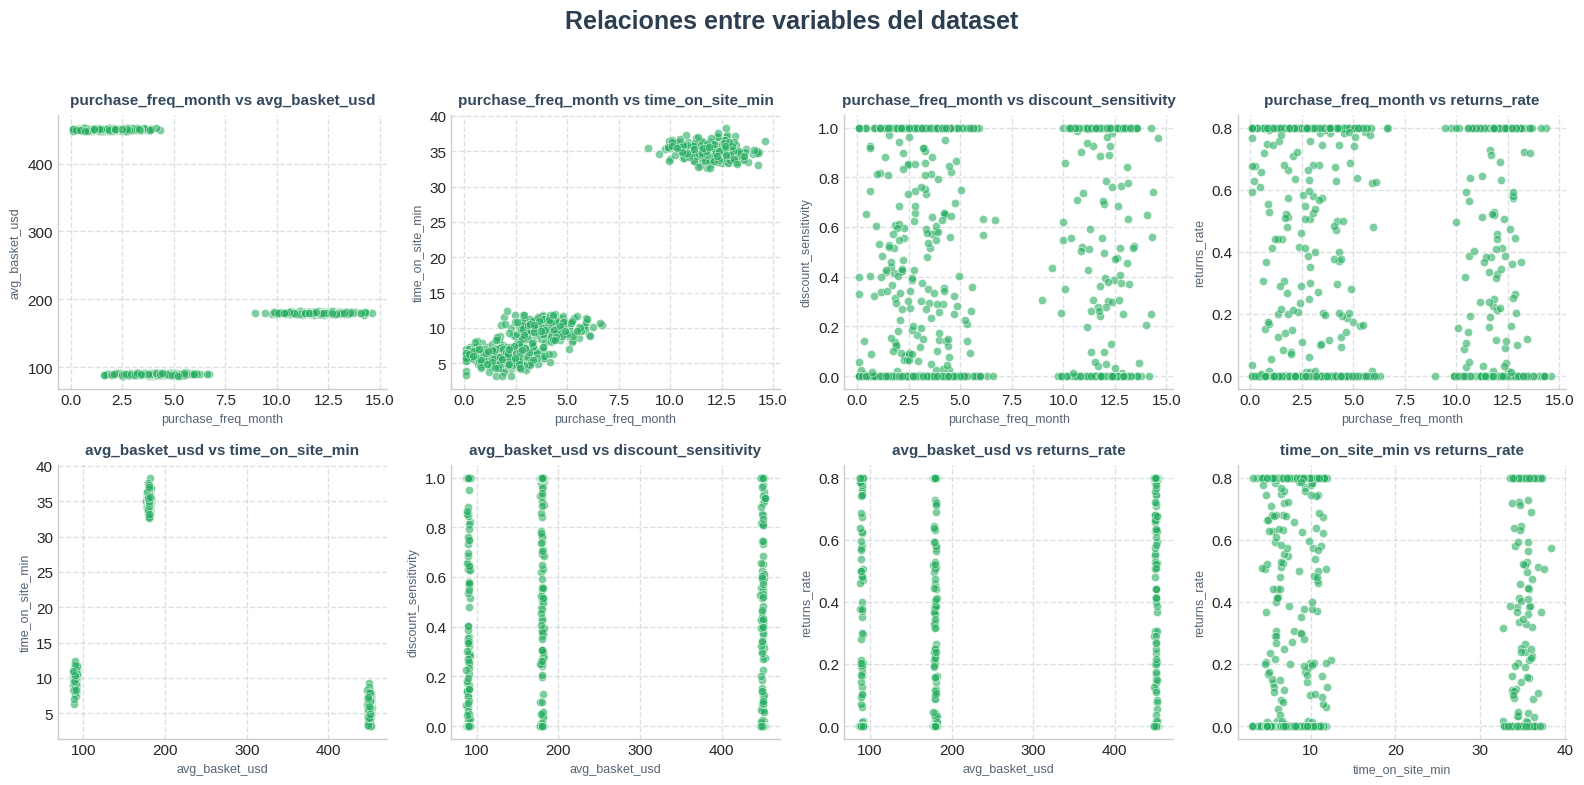

In [7]:
import matplotlib.pyplot as plt

# CONFIGURACIÓN DE ESTILO
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axs = plt.subplots(2, 4, figsize=(16, 8))

vars = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate"
]

pairs = [
    (0,1), (0,2), (0,3), (0,4),
    (1,2), (1,3), (1,4), (2,4)
]

fig.suptitle("Relaciones entre variables del dataset", fontsize=18, fontweight='bold', color='#2c3e50', y=0.98)

# PALETA DE COLORES (Verde Esmeralda)
point_color = '#27ae60'
edge_color = '#1e8449'

for ax, (i, j) in zip(axs.flat, pairs):
    ax.scatter(
        datos_csv_limpios[vars[i]],
        datos_csv_limpios[vars[j]],
        alpha=0.6,
        color=point_color,
        s=35,
        edgecolors='white',
        linewidths=0.5
    )

    ax.set_title(f"{vars[i]} vs {vars[j]}", fontsize=11, fontweight='semibold', color='#34495e', pad=8)
    ax.set_xlabel(vars[i], fontsize=9, color='#566573')
    ax.set_ylabel(vars[j], fontsize=9, color='#566573')

    ax.grid(True, linestyle='--', alpha=0.5, color='#bdc3c7')

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Mejores relaciones entre variables detectadas en el dataset:

1. `purchase_freq_month` vs  `avg_basket_usd`
2. `purchase_freq_month` vs `time_on_site_min`
3. `avg_basket_usd` vs `time_on_site_min`

---

Las variables `discount_sensitivity` (sensibilidad a los descuentos) y `returns_rate`  (tasa de devoluciones) se muestran altamente dispersas y sin patrones claros (forman nubes uniformes o bandas verticales/horizontales sin tendencia), lo que indica que no guardan una relación fuerte o directa con las demás variables analizadas.



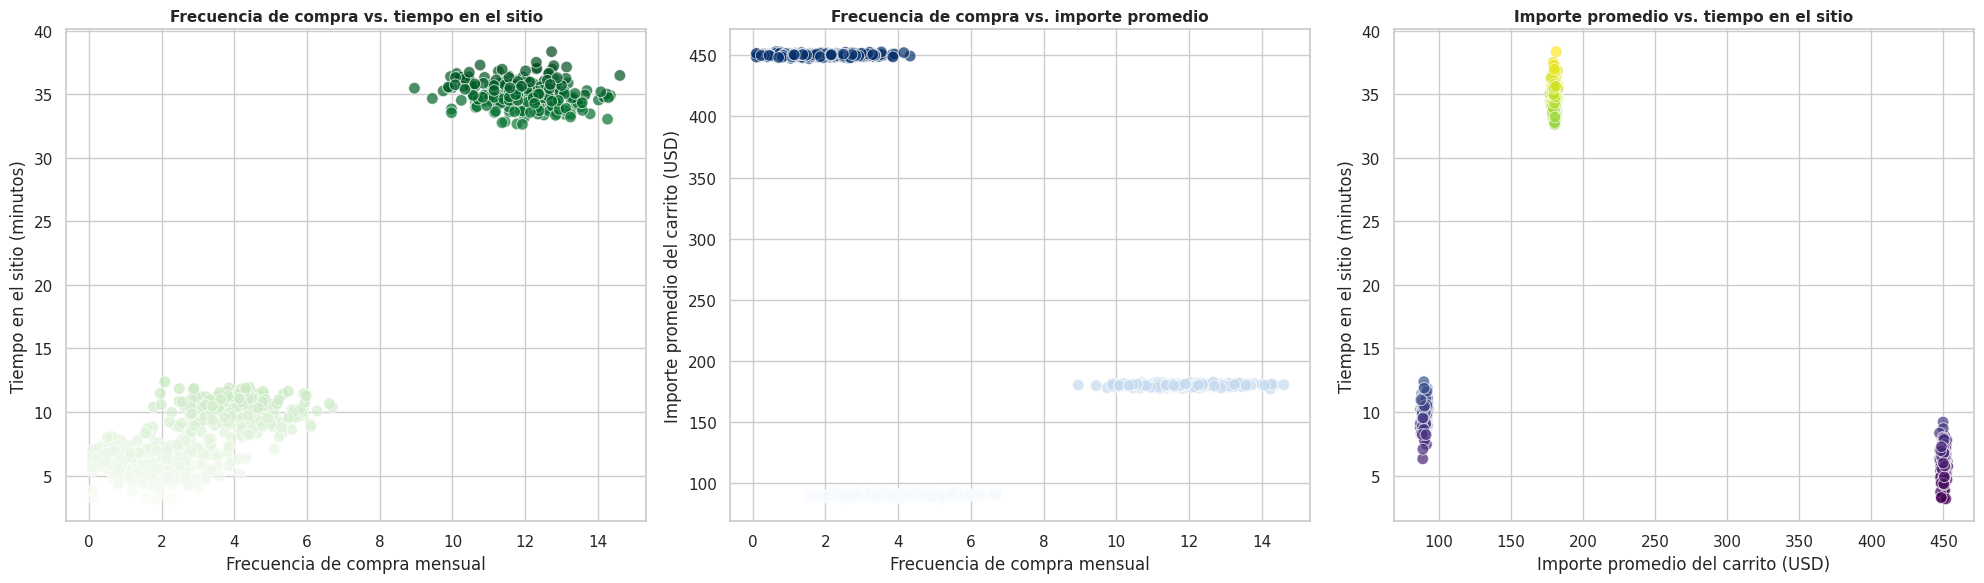

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
sns.set_theme(style="whitegrid")

# Crear figura con tres gráficos
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Frecuencia de compra vs. tiempo en el sitio
sns.scatterplot(
    data=df,
    x='purchase_freq_month',
    y='time_on_site_min',
    hue='time_on_site_min',
    palette='Greens',
    legend=False,
    s=70,
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title(
    'Frecuencia de compra vs. tiempo en el sitio',
    fontsize=11,
    fontweight='bold'
)
axes[0].set_xlabel('Frecuencia de compra mensual')
axes[0].set_ylabel('Tiempo en el sitio (minutos)')

# 2. Frecuencia de compra vs. importe promedio del carrito
sns.scatterplot(
    data=df,
    x='purchase_freq_month',
    y='avg_basket_usd',
    hue='avg_basket_usd',
    palette='Blues',
    legend=False,
    s=70,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title(
    'Frecuencia de compra vs. importe promedio',
    fontsize=11,
    fontweight='bold'
)
axes[1].set_xlabel('Frecuencia de compra mensual')
axes[1].set_ylabel('Importe promedio del carrito (USD)')

# 3. Importe promedio del carrito vs. tiempo en el sitio
sns.scatterplot(
    data=df,
    x='avg_basket_usd',
    y='time_on_site_min',
    hue='time_on_site_min',
    palette='viridis',
    legend=False,
    s=70,
    alpha=0.7,
    ax=axes[2]
)
axes[2].set_title(
    'Importe promedio vs. tiempo en el sitio',
    fontsize=11,
    fontweight='bold'
)
axes[2].set_xlabel('Importe promedio del carrito (USD)')
axes[2].set_ylabel('Tiempo en el sitio (minutos)')

# Ajustar distribución y mostrar
plt.tight_layout()
plt.show()

## Segun las visualizaciones, hay 3 grupos que clientes definidos.

Hipotesis: En un contexto de departamento de ventas de un sitio, según estas visualizaciones, el jefe del equipo de ventas propone que puede haber 3 grupos que clientes latentes, caracterizados por combinaciones de comportamiento de compra, ticket promedio (avg_basket_usd), tiempo en el sitio (time_on_site_min)  y sensibilidad a descuentos (discount_sensitivity). Necesitan validar la hipótesis, se realizará con un modelo de K-Means.

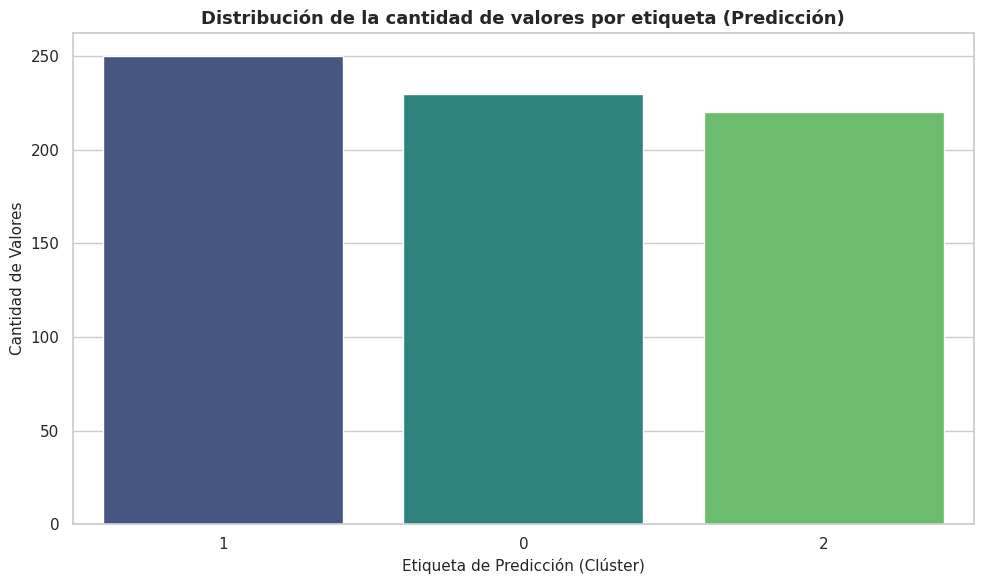

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Preparar y escalar los datos para poder predecir los clústeres
features = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate",
]
X = datos_csv_limpios[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Entrenar K-Means con K = 3 y crear la columna 'cluster' que faltaba
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
datos_csv_limpios["cluster"] = kmeans.fit_predict(X_scaled)

# Configuración general de visualización
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# Gráfico de barras para contar las ocurrencias por cada clúster predicho
sns.countplot(
    data=datos_csv_limpios,
    x='cluster',  # Ahora la columna 'cluster' sí existe
    palette='viridis',
    order=datos_csv_limpios['cluster'].value_counts().index # Ordena de mayor a menor frecuencia
)

plt.title('Distribución de la cantidad de valores por etiqueta (Predicción)', fontsize=13, fontweight='bold')
plt.xlabel('Etiqueta de Predicción (Clúster)', fontsize=11)
plt.ylabel('Cantidad de Valores', fontsize=11)

plt.xticks(rotation=0, ha='center') # Rota las etiquetas si es necesario
plt.tight_layout()
plt.show()


# IMPLEMENTACIÓN DE MODELO K-MEANS:

## Selección y escalado de las caracteristicas - (Se utiliza StandarsScaler)

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Selección y Escalado de características
features = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate",
]
X = datos_csv_limpios[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Evaluación de K óptimo (Inercia y Silhouette)

In [11]:
# 2. Evaluación de K (Inercia y Silhouette)
wcss = []
silhouette_scores = []
K_range = range(2, 6)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

## Visualización del Método del Codo y Silhouette

### Codo: busca el quiebre elijiendo el menor k (modelo más simple)

### Silhouette: elige el k con máximo promedio y clusters con barras consistentes en el gráfico de silhouette.

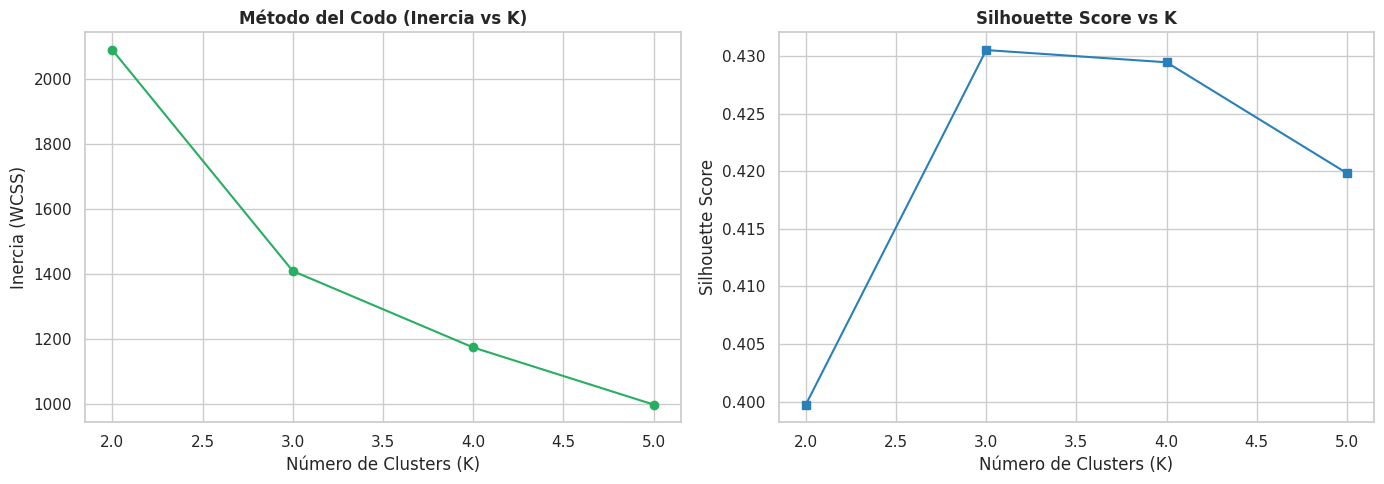

K = 2 | Silhouette Score: 0.3997
K = 3 | Silhouette Score: 0.4305
K = 4 | Silhouette Score: 0.4295
K = 5 | Silhouette Score: 0.4198


In [12]:
# 3. Visualización del Método del Codo y Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico del Codo
ax1.plot(K_range, wcss, marker="o", color="#27ae60")
ax1.set_title("Método del Codo (Inercia vs K)", fontweight="bold")
ax1.set_xlabel("Número de Clusters (K)")
ax1.set_ylabel("Inercia (WCSS)")

# Gráfico de Silhouette
ax2.plot(K_range, silhouette_scores, marker="s", color="#2980b9")
ax2.set_title("Silhouette Score vs K", fontweight="bold")
ax2.set_xlabel("Número de Clusters (K)")
ax2.set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Imprimir resultados
for k, score in zip(K_range, silhouette_scores):
    print(f"K = {k} | Silhouette Score: {score:.4f}")

## Selección del valor óptimo de K

### El valor óptimo de K es 3, es el mejor desempeño del modelo según los criterios de evaluación utilizados.

### La existencia de 3 segmentos y el análisis cuantitativo muestra que K = 3 maximiza la separación y cohesión de los clústeres en este rango analizado.

### Los datos confirman la existencia de esos 3 grupos latentes de clientes de manera óptima.

## Entrenamiento del modelo con el K=3 ÓPTIMO.

In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Seleccionar las variables de comportamiento y estandarizar
features = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate",
]
X = datos_csv_limpios[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Entrenar K-Means con K = 3
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
datos_csv_limpios["cluster"] = kmeans.fit_predict(X_scaled)

# 3. Ver cuántos clientes quedaron en cada clúster
print("--- Cantidad de clientes por segmento ---")
print(datos_csv_limpios["cluster"].value_counts().sort_index())

# 4. Ver los centroides en la escala original para interpretar los perfiles
centroides_escalados = kmeans.cluster_centers_
centroides_originales = scaler.inverse_transform(centroides_escalados)

df_centroides = pd.DataFrame(centroides_originales, columns=features)
df_centroides.index.name = "Cluster"
print("\n--- Centroides de los 3 Segmentos (Valores Promedio) ---")
display(df_centroides)

--- Cantidad de clientes por segmento ---
cluster
0    230
1    250
2    220
Name: count, dtype: int64

--- Centroides de los 3 Segmentos (Valores Promedio) ---


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
Cluster,,,,,
0,11.961153,179.999315,35.022131,0.541539,0.332461
1,1.846908,450.123746,5.973739,0.358088,0.375371
2,4.091883,89.957567,10.003793,0.379465,0.298761


## Visualización de los centroides con el nuevo modelo - Reducción de Dimensionalidad con PCA

Se utiliza PCA para visualizar los clusters en dos dimensiones.

La distribución de clientes: Cuántos clientes caen en cada uno de los 3 grupos.

Los centroides: Los valores promedio reales (frecuencia de compra, ticket en USD, tiempo, sensibilidad y devoluciones) de cada segmento, lo que te permitirá contrastar directamente si coinciden con los perfiles.

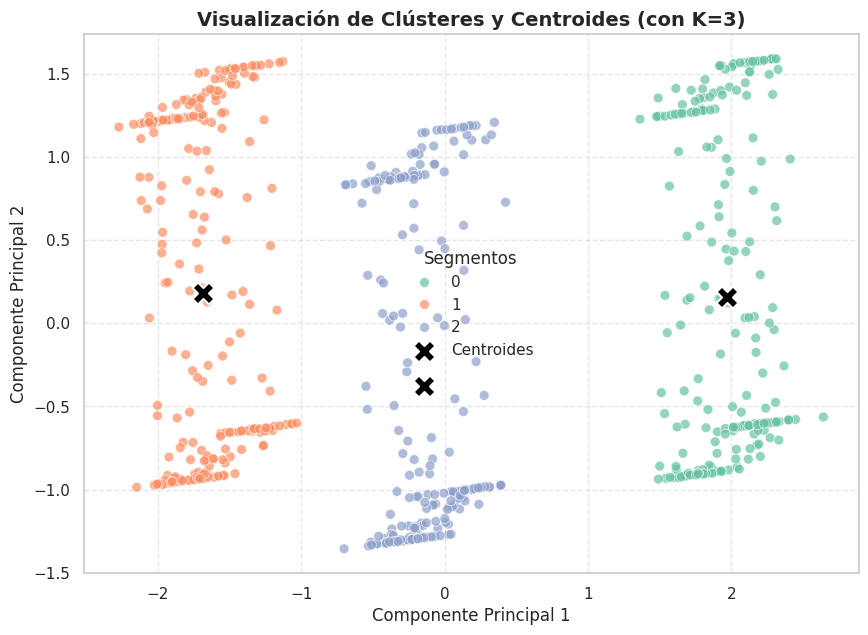

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Preparar los datos y escalar
features = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate",
]
X = datos_csv_limpios[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Entrenar K-Means con K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
datos_csv_limpios["cluster"] = kmeans.fit_predict(X_scaled)

# 3. Reducir dimensionalidad a 2D con PCA para poder graficarlos
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Proyectar también los centroides al espacio PCA
centroides_pca = pca.transform(kmeans.cluster_centers_)

# Crear un DataFrame para la visualización
df_visual = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_visual["cluster"] = datos_csv_limpios["cluster"].values

# 4. Graficar los clústeres y los centroides
plt.figure(figsize=(10, 7))

# Gráfico de dispersión de los puntos (clientes)
sns.scatterplot(
    data=df_visual,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    alpha=0.7,
    s=50,
    edgecolor="w",
)

# Graficar los centroides con una marca distintiva (una "X" negra grande)
plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroides",
    edgecolor="white",
    linewidths=1.5,
)

plt.title(
    "Visualización de Clústeres y Centroides (con K=3)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend(title="Segmentos")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Los puntos de colores: Representan a los diferentes clientes agrupados en sus 3 segmentos según su similitud en el espacio de características.

Las "X" negras grandes ($X$): Representan los centroides (el punto central o "promedio" de cada uno de los 3 clústeres). Esto te permite ver gráficamente si los centros están bien separados entre los grupos o si se solapan.

## Estructura Interna de los Datos:

Dentro de cada grupo vertical se aprecian líneas o bandas de puntos; esto es el reflejo de cómo las variables originales (como la frecuencia de compra o el ticket promedio) se distribuyen y se proyectan en este espacio bidimensional reducido por PCA.

## Validación de la Hipótesis:

Visualmente, este gráfico comprueba y respalda con éxito la hipótesis de los 3 segmentos. Al no haber un solapamiento caótico entre los grupos, se demuestra que los datos de los clientes se agrupan de forma natural en tres perfiles comerciales bien delimitados, facilitando el diseño de estrategias de marketing específicas para cada uno.

## **Interpretar los grupos**

Analizamos el tamaño de cada clúster y resumimos las variables numéricas originales por grupo.

**Calculo del tamaño:** Muestra cuántos clientes pertenecen a cada grupo y qué porcentaje del total representan.

**Calculo los centroides originales:** Agrupa los datos por clúster y calcula la media de cada variable en su escala original (frecuencia, ticket en USD, tiempo, sensibilidad y devoluciones), permitiéndote perfilar comercialmente a cada segmento.

In [15]:
import pandas as pd

# 1. Tamaño y porcentaje de clientes por cada clúster
tamano_clusters = pd.DataFrame({
    'Cantidad de Clientes': datos_csv_limpios['cluster'].value_counts(),
    'Porcentaje (%)': (datos_csv_limpios['cluster'].value_counts(normalize=True) * 100).round(2)
}).sort_index()

print("--- Tamaño y Distribución de los Clústeres ---")
display(tamano_clusters)

# 2. Resumen (promedios) de las variables numéricas originales por cada clúster
features = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate"
]

resumen_clusters = datos_csv_limpios.groupby('cluster')[features].mean().round(2)

print("\n--- Valores Promedio por Clúster (Centroides Originales) ---")
display(resumen_clusters)

--- Tamaño y Distribución de los Clústeres ---


,Cantidad de Clientes,Porcentaje (%)
cluster,,
0,230,32.86
1,250,35.71
2,220,31.43



--- Valores Promedio por Clúster (Centroides Originales) ---


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


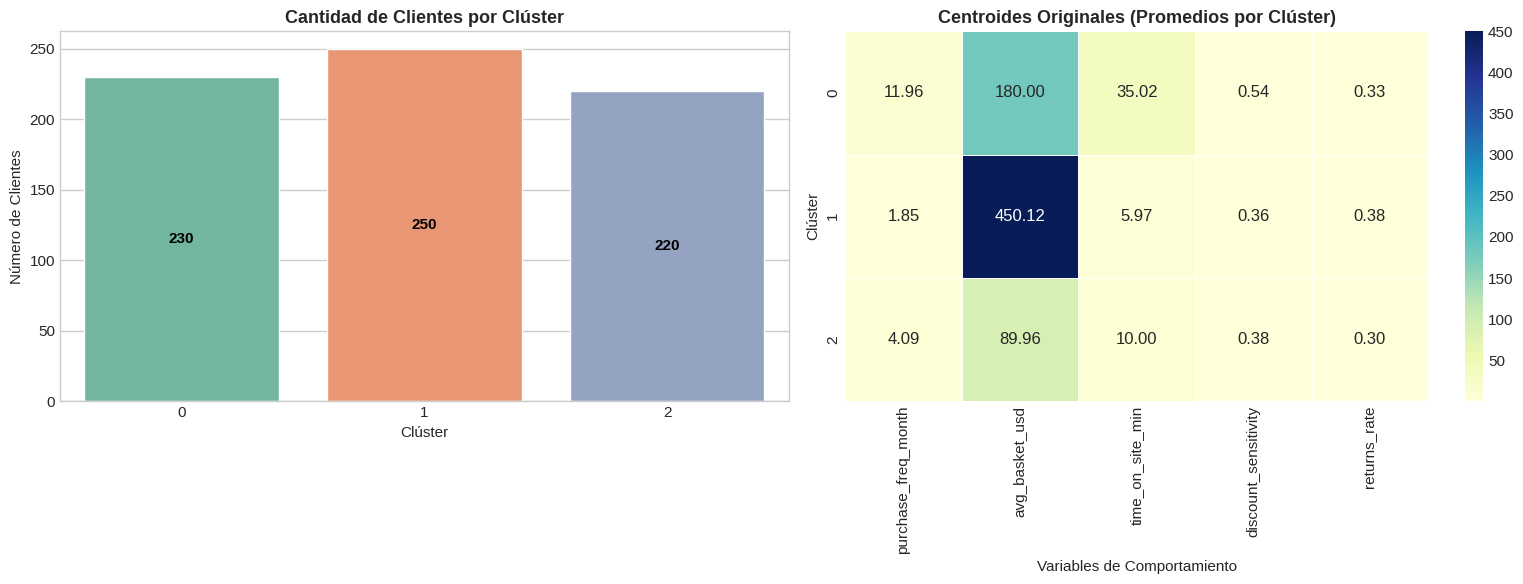

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de barras: Cantidad de clientes por clúster
cluster_counts = datos_csv_limpios["cluster"].value_counts().sort_index()
sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values,
    ax=axes[0],
    palette="Set2",
)
axes[0].set_title(
    "Cantidad de Clientes por Clúster", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Clúster", fontsize=11)
axes[0].set_ylabel("Número de Clientes", fontsize=11)

for p in axes[0].patches:
  axes[0].annotate(
      f"{int(p.get_height())}",
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2),
      ha="center",
      va="center",
      fontsize=11,
      color="black",
      fontweight="bold",
  )

# 2. Gráfico de calor (Heatmap): Centroides (Valores Promedio por Clúster)
features = [
    "purchase_freq_month",
    "avg_basket_usd",
    "time_on_site_min",
    "discount_sensitivity",
    "returns_rate",
]
centroides_df = datos_csv_limpios.groupby("cluster")[features].mean()

sns.heatmap(
    centroides_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar=True,
    ax=axes[1],
    linewidths=0.5,
)
axes[1].set_title(
    "Centroides Originales (Promedios por Clúster)",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Variables de Comportamiento", fontsize=11)
axes[1].set_ylabel("Clúster", fontsize=11)

plt.tight_layout()
plt.show()

**Gráfico de barras izquierdo:** La distribución exacta de la cantidad de clientes que conforman cada uno de los 3 segmentos.

**Mapa de calor derecho:** Los valores promedio (centroides originales) de cada variable por clúster, lo que te permitirá identificar de un vistazo rápido qué grupo compra más frecuentemente, cuál tiene mayor ticket o mayor sensibilidad a descuentos.

---


## **CONCLUSIONES:**


En este trabajo se aplicó el algoritmo **K-Means** para realizar una segmentación de clientes a partir de variables relacionadas con la frecuencia de compra, el ticket promedio, el tiempo en el sitio web, la sensibilidad a los descuentos y la tasa de devoluciones.

### 1. Preparación de los datos
Se eliminaron las variables de ruido y se escalaron los datos para evitar que las diferencias de magnitud entre las variables afectaran el cálculo de las distancias, fundamental para el funcionamiento de K-Means.

### 2. Selección del número de clústeres
Se compararon distintos valores de *k*, entre 2 y 6, mediante el **Método del Codo**. A partir de este análisis, se seleccionó **k = 3** como una alternativa razonable para obtener una segmentación interpretable sin generar una cantidad excesiva de grupos y se volvió a entrenar el modelo con este parámetro.

### 3. Interpretación de los segmentos
El análisis de los centroides y la visualización con mapa de calor permitió identificar tres perfiles de clientes:

- **Clientes frecuentes sensibles a las promociones:** realizan compras con mayor frecuencia y muestran sensibilidad a los descuentos.
- **Muy buenos clientes con pocas compras pero de mayor importe:** realizan compras menos frecuentes, pero presentan un ticket promedio elevado.
- **Clientes ocasionales que gastan menos:** se caracterizan por una menor frecuencia de compra y un ticket promedio más bajo.

### 4. Resultado final
La aplicación de K-Means permitió identificar grupos de clientes con características similares sin necesidad de utilizar etiquetas previamente definidas. De esta manera, el aprendizaje no supervisado cumplió con el objetivo de la actividad: **descubrir segmentos de clientes y facilitar la interpretación de sus comportamientos de compra**.


### **Confirmación de la Hipótesis:**

* La hipótesis planteada por el equipo de ventas —que proponía la existencia de **3 segmentos latentes de clientes**— quedó totalmente **validada y confirmada** por el modelo de aprendizaje no supervisado (**K-Means**).

* La métrica del **Coeficiente de Silhouette** alcanzó su punto óptimo en $K = 3$ ($0.4305$), demostrando que dividir los datos en 3 grupos maximiza la cohesión interna y la separación entre segmentos frente a otras alternativas ($K=2, 4, 5$).
